# OISST over the equatorial Pacific: the Nino 3.4 box from heatwaves to El Nino objects

NOAA OISST over 5°S–5°N and 170°W–120°W (40 x 200 cells at 0.25°, all ocean), 1991–2025, with the fixed 1991–2020 climatology. Marine heatwaves and cold spells are detected per cell with their own percentile tails, compared with a retrospective detrended baseline, and the heatwave membership is tracked as objects. The strong El Ninos of 1997–98 and 2015–16 and the event of 2023 appear as very large, long-lived objects that can cover most of the box. Reproduced numbers are pending scientific review.

Read [the tutorial guide](../docs/TUTORIALS.md#oisst-equatorial-pacific) for inputs and results. Saved outputs can be read without data; re-execution needs the compressed OISST equatorial dataset of [the README](../README.md), about 8 minutes and about 8 GB of memory. No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | NOAA OISST v2.1 AVHRR-only, equatorial Pacific (stored-content hash in report.json) |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | executed; summaries pending scientific review |

Fixed and detrended baselines use identical definitions. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/oisst_equatorial.json).

In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = (
    Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "oisst_equatorial"
)
# Optional: XHW_MAPPED_ARRAYS=1 before starting this kernel (docs/REPRODUCIBILITY.md).

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from dataclasses import replace

from _data import load_oisst_equatorial, marine_definition
from _report import lineage_catalog_status, spatial_summary, temporal_summary, write_report
from array_storage import enabled, mapped_array, mapped_intensity, mapped_product, reuse_temperature
from plotting import (
    frequency_figure,
    genealogy_figure,
    largest_event,
    metrics_figure,
    sequence_figure,
    series_figure,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Open the checked daily SST subset

The compressed dataset is verified by its stored content before use. Interpolation of short gaps is explicit and fills nothing here. The box is 40 x 200 cells, all ocean.

In [4]:
raw, grid, baseline, definition = load_oisst_equatorial(data_dir)
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(raw)
storage = output_dir / "_arrays" if enabled() else None
if storage is not None:
    raw["sst"] = mapped_array(raw.sst, storage, "raw-sst")
print("NOAA OISST v2.1; equatorial Pacific 1991–2025; reference 1991–2020; checked input.")
prepared = xhw.interpolate_gaps(
    raw, variable="sst", grid=grid, max_days=2, max_filled_fraction=0.05
)

NOAA OISST v2.1; equatorial Pacific 1991–2025; reference 1991–2020; checked input.


## Marine heatwaves and cold spells use distinct percentile tails

MHW uses strict P90 exceedance; MCS uses strict P10 under-threshold comparison. Both use 11-day pooling, 31-day smoothing, type 7, minimum five days and gaps up to two days, qualifying runs before joining. Frequency uses valid-day support.

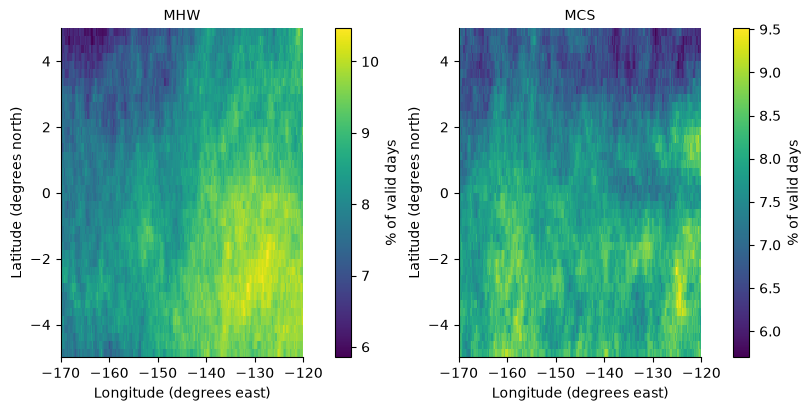

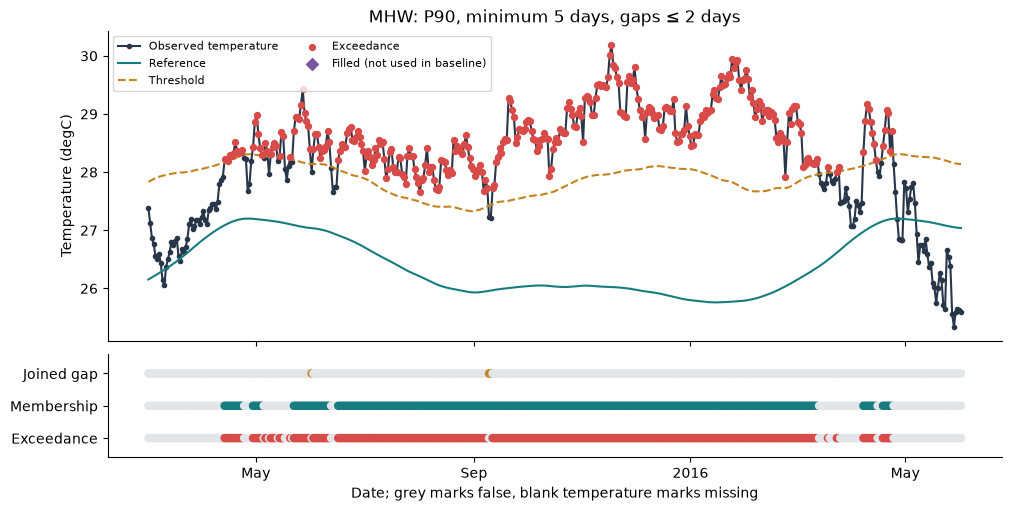

In [5]:
masks, catalogs, metrics, fits = {}, {}, {}, {}
for name, detector in (("MHW", definition), ("MCS", marine_definition(cold=True))):
    fitted = xhw.fit_baseline(
        prepared, variable="sst", grid=grid, baseline=baseline, definition=detector
    )
    fitted.check_invariants()
    fits[name] = fitted
    masks[name] = xhw.detect(
        prepared, variable="sst", grid=grid, definition=detector, baseline_result=fitted
    )
    if storage is not None:
        masks[name] = mapped_product(masks[name], storage, name)
        if name == "MHW":
            reuse_temperature(prepared, masks[name])
    masks[name].check_invariants()
    catalogs[name] = xhw.build_catalog(masks[name], analysis_mode="retrospective")
    catalogs[name].check_against(masks[name])
    metrics[name] = temporal_summary(masks[name], catalogs[name])
mask = masks["MHW"]
figure = frequency_figure(masks, output_dir)
figure = series_figure(
    raw,
    mask,
    variable="sst",
    selection={"lat": 20, "lon": 100},
    period=("2015-03-01", "2016-06-01"),
    output_dir=output_dir,
)

## Compare the same definition with a retrospective detrended baseline

Only the baseline method changes to detrended (degree 1, three harmonics). Both are retrospective; neither is labelled superior. Jaccard uses jointly valid cell-days as support and membership union as denominator.

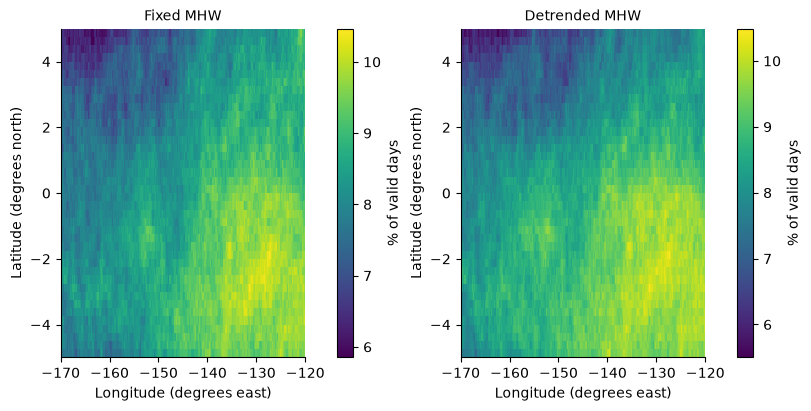

In [6]:
dynamic = replace(baseline, method="detrended")
fitted_dynamic = xhw.fit_baseline(
    prepared, variable="sst", grid=grid, baseline=dynamic, definition=mhw
)
if storage is not None:
    fitted_dynamic = mapped_product(fitted_dynamic, storage, "dynamic-baseline")
fitted_dynamic.check_invariants()
dynamic_mask = xhw.detect(
    prepared, variable="sst", grid=grid, definition=mhw, baseline_result=fitted_dynamic
)
if storage is not None:
    dynamic_mask = mapped_product(dynamic_mask, storage, "dynamic-mask")
dynamic_mask.check_invariants()
dynamic_catalog = xhw.build_catalog(dynamic_mask, analysis_mode="retrospective")
dynamic_catalog.check_against(dynamic_mask)
metrics["detrended"] = temporal_summary(dynamic_mask, dynamic_catalog)
common_valid = mask.dataset.valid & dynamic_mask.dataset.valid
a, b = mask.dataset.event_membership, dynamic_mask.dataset.event_membership
union = int(((a | b) & common_valid).sum())
metrics["fixed_detrended_jaccard"] = float(((a & b) & common_valid).sum()) / union if union else 1.0
figure = frequency_figure(
    {"Fixed MHW": mask, "Detrended MHW": dynamic_mask}, output_dir, name="baseline_comparison"
)

## Track event-membership patches; the default recipe would not track

The default recipe does not track. This explicit recipe uses event membership, face-connected patches at least 5% of ocean area, any positive overlap and minimum five-day tracks. In this small box a strong El Nino is one patch covering most of it.

3071009346.py:10: XHWDataQualityWarning: min_area (domain_fraction 5) discards 59434 of 61814 patches (96 %): the cut (3.08716e+11 m2) may not suit the size of this domain; check `MinArea` (a percentile or a smaller fraction scales better to large domains)
  objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")


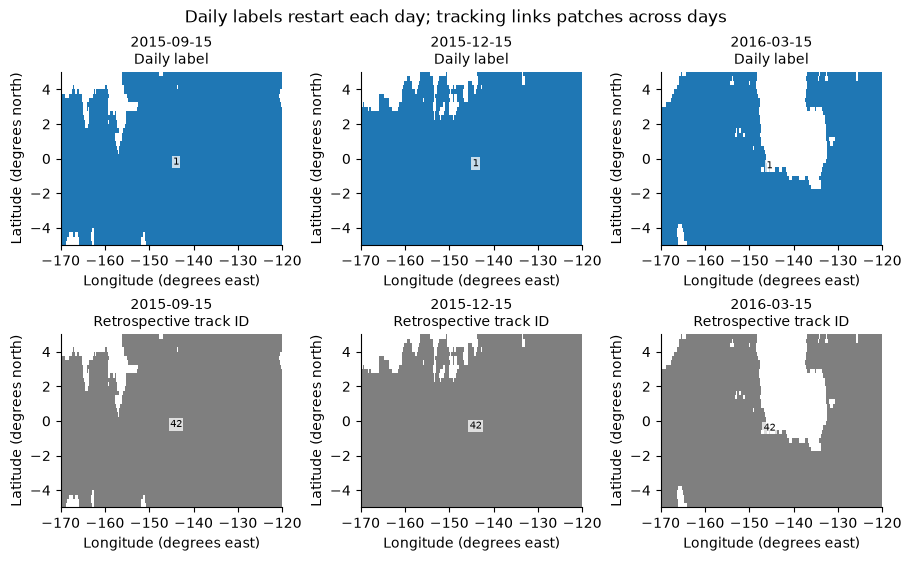

In [7]:
recipe = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.segment(
            footprint=xhw.Footprint.connected(1), min_area=xhw.MinArea.default()
        ),
        xhw.RecipeStep.track(min_overlap=0.0, max_gap_days=0, min_duration_days=5),
    ),
)
objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
figure = sequence_figure(objects, ["2015-09-15", "2015-12-15", "2016-03-15"], output_dir)

## Derive branches and spacetime events with area-weighted intensity

Intensity is temperature minus reference. Sizes and means are area weighted. The graph includes all patch labels; short components can prevent qualified EventCatalog export in 0.1.0. That constraint is recorded, while graph invariants are checked.

Catalog export constraint: 24 graph components are shorter than 5 days. Use graph.dataset for these components.


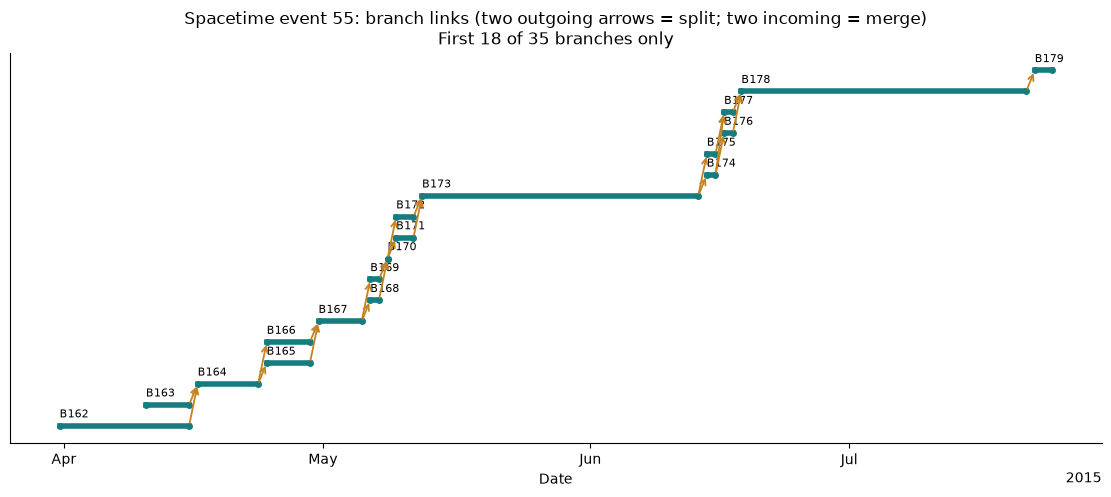

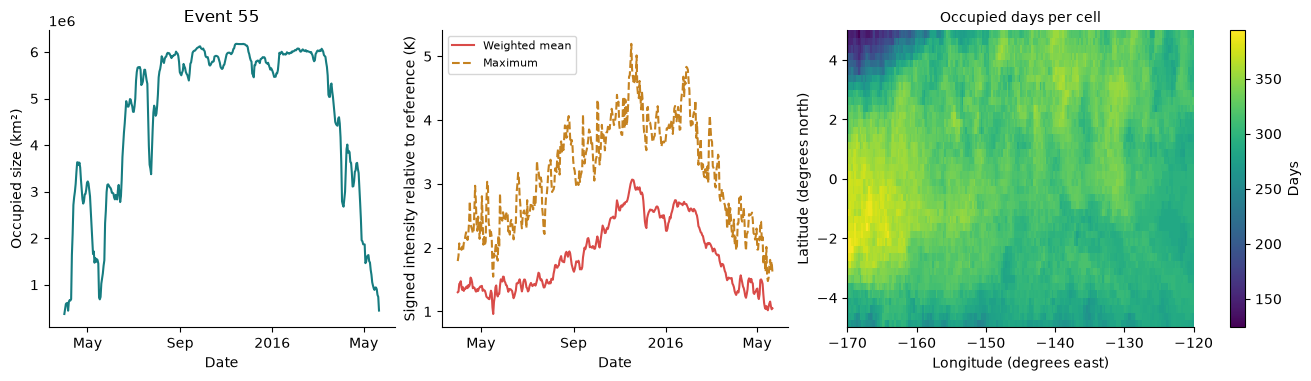

In [8]:
intensity = mapped_intensity(mask, storage, "intensity") if storage else mask.intensity()
graph = xhw.build_lineage(objects, field=intensity, weighted=True)
graph.check_invariants()
graph.check_against(objects)
metrics["lineage_catalog_export"] = lineage_catalog_status(graph, mask)
event = largest_event(graph)
figure = genealogy_figure(graph, event, output_dir)
metrics_figure(graph, objects, event, output_dir)
del figure
metrics["spatial"] = spatial_summary(objects, graph)
metrics["largest_size_time_event"] = int(event)

## Preserve the distinction between reproduced output and scientific approval

Reproduced output is not scientific approval: summaries stay pending review.

In [9]:
report = write_report(
    output_dir,
    "oisst_equatorial",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=recipe,
    graph=graph,
    review="executed; summaries pending scientific review",
    extra={
        "selection": (
            "Equatorial Pacific (Nino 3.4): latitude -5 to 5; longitude -170 to -120; 1991–2025"
        ),
        "dynamic_baseline": dynamic.to_dict(),
        "comparison_denominator": "union of membership on jointly valid cell-days",
        "common_valid_cell_days": int(common_valid.sum()),
        "source_resolution_degrees": 0.25,
    },
)

{
  "MHW": {
    "events": 376186,
    "exceedance_cell_days": 10882881,
    "event_cell_days": 8688894,
    "joined_cell_days": 135538,
    "valid_cell_days": 102272000,
    "filled_cell_days": 0,
    "max_duration_days": 378
  },
  "MCS": {
    "events": 579809,
    "exceedance_cell_days": 10099450,
    "event_cell_days": 7836939,
    "joined_cell_days": 85936,
    "valid_cell_days": 102272000,
    "filled_cell_days": 0,
    "max_duration_days": 291
  },
  "detrended": {
    "events": 374470,
    "exceedance_cell_days": 10870121,
    "event_cell_days": 8682567,
    "joined_cell_days": 134612,
    "valid_cell_days": 102272000,
    "filled_cell_days": 0,
    "max_duration_days": 381
  },
  "fixed_detrended_jaccard": 0.9320851874471071,
  "lineage_catalog_export": {
    "status": "not exportable as qualified EventCatalog",
    "short_components": 24,
    "reason": "qualified events shorter than min_duration_days"
  },
  "spatial": {
    "patches": 2380,
    "tracks": 58,
    "branches":

## Interpretation and provenance

Inspect the executed report. Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. These are reproduced numbers pending scientific review; figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [10]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.3',
  'xarray': '2026.9.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:a061ff363081818ed36debd7d460899854d7340cdf9fdb2ae80a79112a9ab0fe'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [11]:
from exploration import explorer

cases = {"Fixed MHW": (mask, objects, graph),
         "MCS (temporal products)": (masks["MCS"], None, None),
         "Detrended MHW (temporal products)": (dynamic_mask, None, None)}
explorer(cases)
